In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable

import sys
sys.path.append('../src')

from lib_spike_control import *
from utils import *

plt.style.use('tableau-colorblind10')

cmap = matplotlib.colormaps['PRGn']

In [2]:
# Define grid

grid_max = 20.
n_grid = 20001 

grid = np.linspace(0., grid_max, n_grid, endpoint=True)
target = np.zeros((len(grid),2))

In [3]:
# Set parameters for two different trajectories
 
a = 1
eps0 = 1
theta = 1/1.5
leak = 0.2
kappa_1 = .5
kappa_2 = 3
x0_1 = np.array([10, 0])
x0_2 = np.array([10, 0])

z_1, s_1, x_1, x_cont_1, x_jumps_1, x_c_1 = generate_2d_traj(a, kappa_1, eps0, theta, leak, grid, target, x0_1)
z_2, s_2, x_2, x_cont_2, x_jumps_2, x_c_2 = generate_2d_traj(a, kappa_2, eps0, theta, leak, grid, target, x0_2)

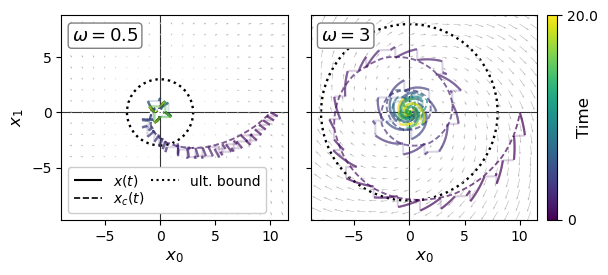

In [5]:
# Variable plot size
resc = .8

# Set up the grid for subplots
fig, ax = plt.subplots(1,2, sharey=True, sharex=True,  figsize=(8*resc,4*resc), gridspec_kw={'wspace': 0.1})

color1 = cmap(0.6)
color2 = cmap(0.2)

cmap = matplotlib.colormaps['viridis']

step = 1
c_array = np.linspace(0,1,n_grid)

# Plot left subplot
colored_line(x_cont_1[:,0], x_cont_1[:,1], c_array, ax[0], cmap=cmap, label='$x(t)$', zorder=4)
colored_line(x_jumps_1[:,0], x_jumps_1[:,1], c_array, ax[0], cmap=cmap, alpha=.2, zorder=4)
colored_line(x_c_1[:,0][::step], x_c_1[:,1][::step], c_array[::step], ax[0], cmap=cmap, linestyle='dashed', lw=1.2, zorder=2, label='$x_c(t)$')
ax[0].plot(x_c_1[:,0][::step], x_c_1[:,1][::step], color='white', lw=2, ls=(0, (1, 2)), zorder=3)

# Plot right subplot
c = colored_line(x_cont_2[:,0], x_cont_2[:,1], c_array, ax[1], cmap=cmap, zorder=4)
colored_line(x_jumps_2[:,0], x_jumps_2[:,1], c_array, ax[1], cmap=cmap, alpha=.2, zorder=4)
colored_line(x_c_2[:,0][::step], x_c_2[:,1][::step], c_array[::step], ax[1], cmap=cmap, linestyle='dashed', lw=1.2, zorder=2)
ax[1].plot(x_c_2[:,0][::step], x_c_2[:,1][::step], color='white', lw=2, ls=(0, (1, 2)), zorder=3)

# Plot ultimate bounds
r1 = ult_bound_2d(a, eps0, theta, kappa_1)
r2 = ult_bound_2d(a, eps0, theta, kappa_2)

circle1 = plt.Circle((0, 0), r1, fill=False, edgecolor='0', ls='dotted', lw=1.7)
ax[0].plot((), (), c='0', ls='dotted', label='ult. bound')
circle2 = plt.Circle((0, 0), r2, fill=False, edgecolor='0', ls='dotted', lw=1.7)

ax[0].add_patch(circle1)
ax[1].add_patch(circle2)

ax[0].set_xlabel('$x_0$', size=12)
ax[1].set_xlabel('$x_0$', size=12)
ax[0].set_ylabel('$x_1$', size=12)

# Plot legend
leg = ax[0].legend(framealpha=1, 
                   #loc=1,
                   ncol=2,
                   #handlelength=1.2,
                   labelspacing=0.1,
                   columnspacing=.5)
for handle in leg.legend_handles:
    if hasattr(handle, "set_color"):
        handle.set_color("black")

   
cbar = plt.colorbar(c, ax=[ax[0],ax[1]], fraction=0.0206, pad=0.02)

cbar.set_label(r'Time', fontsize=12, labelpad=-15)
cbar.set_ticks((0, 1))
cbar.set_ticklabels(('$0$', str(grid_max)))

ax[0].axis("scaled")
ax[1].axis("scaled")

# Store current limits
xlim0 = ax[0].get_xlim()
ylim0 = ax[0].get_ylim()
xlim1 = ax[1].get_xlim()
ylim1 = ax[1].get_ylim()

ax[0].hlines(0,*xlim0, colors='0.2', lw=.8, zorder=1)
ax[0].vlines(0,*ylim0, colors='0.2', lw=.8, zorder=1)
ax[1].hlines(0,*xlim1, colors='0.2', lw=.8, zorder=1)
ax[1].vlines(0,*ylim1, colors='0.2', lw=.8, zorder=1)

# Define uncontrolled vector field

a=1
f = lambda x,y,kappa: np.array([a*x+kappa*y, -kappa*x+a*y])

# Define grid
x = np.linspace(-15, 15, 31)
y = np.linspace(-15, 15, 31)
X, Y = np.meshgrid(x, y)

# Evaluate vector field
U0, V0 = f(X, Y, kappa_1)
U1, V1 = f(X, Y, kappa_2)

sc = 40
# Plot quiver (uniform color, arrows scaled by vector magnitude)
ax[0].quiver(
    X, Y, U0, V0,
    color='.7',         # unicolor
    angles='xy',
    scale_units='xy',
    scale= sc,  # adjust scaling so arrows look good
    zorder=1,
    rasterized=True
)
ax[1].quiver(
    X, Y, U1, V1,
    color='.7',         # unicolor
    angles='xy',
    scale_units='xy',
    scale= sc,  # adjust scaling so arrows look good
    zorder = 1,
    rasterized=True
)


ax[0].text(
    -8,6.5, 
    f'$\\omega = {kappa_1}$',
    fontsize=13,
    bbox=dict(facecolor='white', alpha=1, edgecolor='.5', boxstyle='round,pad=0.2')
)

ax[1].text(
    -8,6.5, 
    f'$\\omega = {kappa_2}$',
    fontsize=13,
    bbox=dict(facecolor='white', alpha=1, edgecolor='.5', boxstyle='round,pad=0.2')
)

ax[0].set_xlim(xlim0)
ax[0].set_ylim(ylim0)
ax[1].set_xlim(xlim1)
ax[1].set_ylim(ylim1)

ax[0].set_rasterization_zorder(10)
ax[1].set_rasterization_zorder(10)

plt.savefig('../plots/figure3.svg', dpi=400, bbox_inches='tight')